In [1]:
# Import the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report,f1_score
print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Load the iris dataset
iris = load_iris(as_frame=True)

# Create the feature dataset
x = iris.data

# Create the target dataset
y = iris.target

# Combine features and targets into one DataFrame
df = iris.frame

print("Dataset loaded sucessfully!")


Dataset loaded sucessfully!


In [4]:
# Display the first five rows
display(df.head())

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check the column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check the target classes
print("\nFlower Species:")
print(iris.target_names)

# Check the feature names
print("\nFeature Names:")
print(iris.feature_names)
#

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Dataset shape: (150, 5)

Column Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target']

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Flower Species:
['setosa' 'versicolor' 'virginica']

Feature Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [6]:
# Generate descriptive statistics

print("Dataset summary")
print(df.describe())

# Check the distribution of flower species

print("\nNumber of samples in each species:")
print(df['target'].value_counts().sort_index())

Dataset summary
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)      target  
count        150.000000  150.000000  
mean           1.199333    1.000000  
std            0.762238    0.819232  
min            0.100000    0.000000  
25%            0.300000    0.000000  
50%            1.300000    1.000000  
75%            1.800000    2.000000  
max            2.500000    2.000000  

Number of samples in each species:
target
0    50
1    

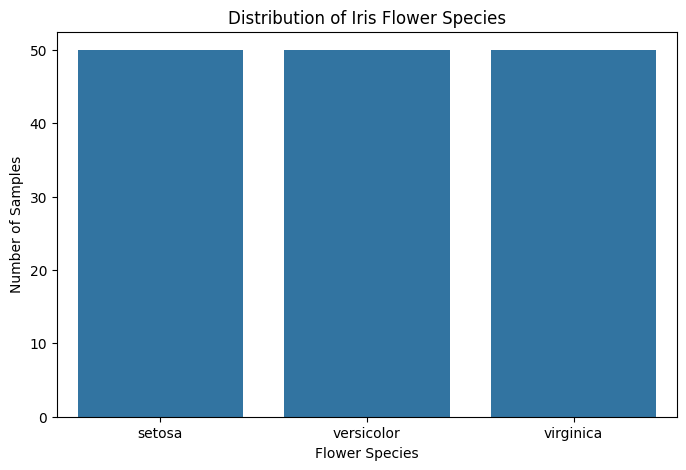

In [8]:
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))

# Visualize the number of flowers in each species

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='species')

plt.title('Distribution of Iris Flower Species')
plt.xlabel('Flower Species')
plt.ylabel('Number of Samples')

plt.show()

In [9]:
# Split the dataset into training and testing sets

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42,stratify=y)

print("Data splitting completed sucessfully")

print("\nTraining features:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing features:", x_test.shape)
print("Testing labels:", y_test.shape)

Data splitting completed sucessfully

Training features: (120, 4)
Training labels: (120,)
Testing features: (30, 4)
Testing labels: (30,)


In [11]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit the scaler to the training data and transform it
x_train_scaled = scaler.fit_transform(x_train)

# Transform the testing data using the same scaler
x_test_scaled = scaler.transform(x_test)

# Display the shapes to confirm successful scaling
print("Original training data shape:", x_train.shape)
print("Scaled training data shape:", x_train_scaled.shape)

print("\nOriginal testing data shape:", x_test.shape)
print("Scaled testing data shape:", x_test_scaled.shape)

Original training data shape: (120, 4)
Scaled training data shape: (120, 4)

Original testing data shape: (30, 4)
Scaled testing data shape: (30, 4)


In [15]:
# Check the mean and standard deviation of scaled training features

print("Mean of scaled training features:")
print(x_train_scaled.mean(axis=0))

print("\nStandard deviation of scaled training features:")
print(x_train_scaled.std(axis=0))


Mean of scaled training features:
[-1.36927506e-16  9.99200722e-16  1.66533454e-17  1.70234197e-16]

Standard deviation of scaled training features:
[1. 1. 1. 1.]


In [32]:
# Create the KNN model (KNeighborsClassifier is already imported from sklearn.neighbors)
model = KNeighborsClassifier(n_neighbors=5)

In [20]:
# Train the model using the training data
model.fit(x_train, y_train)

print("Model training completed sucessfully")

Model training completed sucessfully


In [23]:
# Make predictions on the scaled test set
y_pred = model.predict(x_test_scaled)

print("Prediction:")
print(y_pred)

Prediction:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 1 2 1 1 0 2 0]


In [24]:
from sklearn.metrics import accuracy_score

# Calculate the accuracy
accuracy = accuracy_score(y_test, y_pred)
print(" Model Accuracy:", accuracy)
print("Model Accuracy Percentage:", accuracy * 100, "%")

 Model Accuracy: 0.9333333333333333
Model Accuracy Percentage: 93.33333333333333 %


In [28]:
from sklearn.metrics import confusion_matrix

# Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]


In [31]:
from sklearn.metrics import classification_report

# Generate the classification report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.83      1.00      0.91        10
           2       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

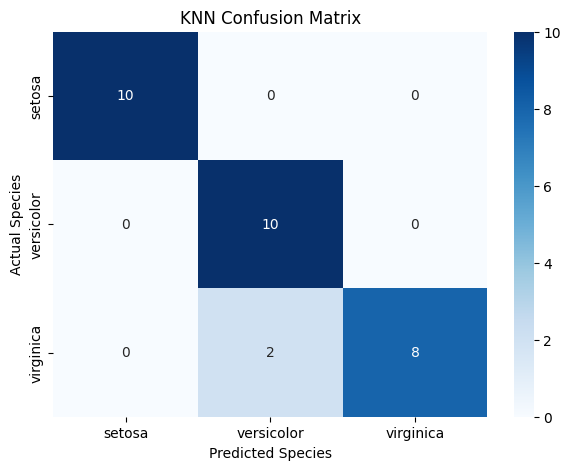

In [34]:
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("KNN Confusion Matrix")

plt.show()


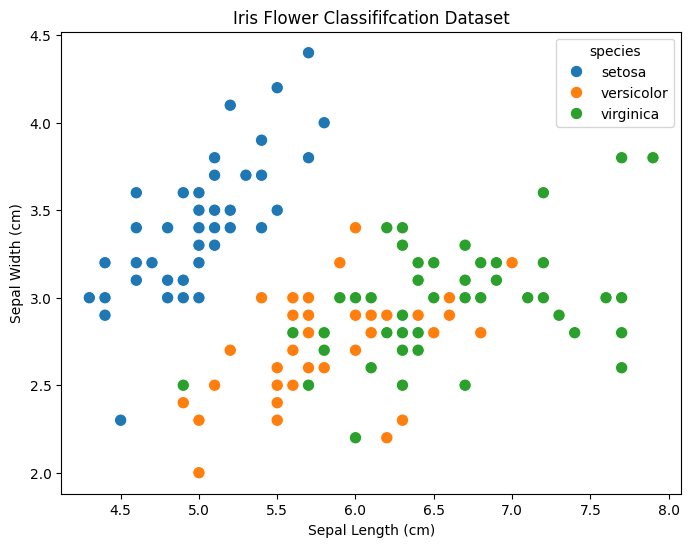

In [35]:
# Visualize the iris dataset

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='sepal length (cm)', y='sepal width (cm)', hue='species', s=80)

plt.title('Iris Flower Classififcation Dataset')
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')

plt.show()

In [36]:
# New flower measurements
new_flower = [[5.1, 3.5, 1.4, 0.2]]

print("New flower measurements:", new_flower)

New flower measurements: [[5.1, 3.5, 1.4, 0.2]]


In [38]:
# Apply the previously fitted scaler
new_flower_scaled = scaler.transform(new_flower)

print("Scaled new flower measurements:")
print(new_flower_scaled)

Scaled new flower measurements:
[[-0.88566202  1.01122923 -1.34572231 -1.32327558]]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [42]:
# Fit the model using the scaled training data first
model.fit(x_train_scaled, y_train)

# Predict the species
prediction = model.predict(new_flower_scaled)

# Display the predicted flower species
predicted_species = iris.target_names[prediction[0]]

print("Predicted Flower Species:", predicted_species)

Predicted Flower Species: setosa


In [43]:
import joblib

In [45]:
# Save the trained KNN model
joblib.dump(model, 'knn_model.pkl')

print("KNN model saved successfully")


KNN model saved successfully


In [49]:
# save the fitted scaler
joblib.dump(scaler, 'iris scaler.pkl')

print("Scaler saved successfully")

Scaler saved successfully


In [50]:
from google.colab import files

files.download('knn_model.pkl')
files.download('iris scaler.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [52]:
# Load the saved KNN model
loaded_model = joblib.load("knn_model.pkl")

print("Saved KNN model loaded successfully!")

Saved KNN model loaded successfully!


In [54]:
# New flower measurements
new_flower = [[6.3, 3.3, 4.7, 1.6]]

# Load the saved scaler
loaded_scaler = joblib.load("iris scaler.pkl")

# Scale the measurements
new_flower_scaled = loaded_scaler.transform(new_flower)

# Predict using the loaded model
prediction = loaded_model.predict(new_flower_scaled)

# Display the prediction
predicted_species = iris.target_names[prediction[0]]

print("Predicted Flower Species:", predicted_species)

Predicted Flower Species: versicolor


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [55]:

original_prediction = model.predict(new_flower_scaled)
loaded_prediction = loaded_model.predict(new_flower_scaled)

print("Original Model Prediction:", original_prediction)
print("Loaded Model Prediction:", loaded_prediction)

print("Both models agree:",
      (original_prediction == loaded_prediction).all())


Original Model Prediction: [1]
Loaded Model Prediction: [1]
Both models agree: True
